# 04 — Localización Espacial en la Arena, Zonas y Construcción del Dataset VLM

Este notebook completa el **Paso 4B** del pipeline conectando los resultados previos de Cloudflare R2:
1. **Consume los manifiestos de R2:**
   - `metadata/extracted_events.json` o `metadata/events/<video_id>.json` (Notebook 03: segundo exacto `t_drop_sec`, `t_decision_sec`, slot y carta jugada).
   - `metadata/ui_layouts.json` (Notebook 02: coordenadas exactas de `arena_box`).
   - `metadata/cards_catalog.json` (Notebook 00: tipo de carta `Troop`, `Building`, `Spell`).
2. **Localización en Arena por la ETIQUETA FLOTANTE del nombre de la carta (señal principal):**
   - Al soltar una carta propia, el juego dibuja su nombre (blanco, o dorado si tiene nivel estelar) con contorno oscuro y la línea `Nvl. XX` justo encima del punto de despliegue. Aparece en el **destino real** (torre rival para *Excavadora/Minero/Barril*, centro del campo para estructuras como la *Torre infernal*), por lo que es inmune a peleas en los puentes y a túneles/proyectiles en vuelo.
   - Se buscan píxeles de texto **nuevos** en $[t_{\text{drop}} - 0.45\text{ s}, t_{\text{drop}} + 0.35\text{ s}]$ respecto a un fondo en $t_{\text{drop}} - 1.6\text{ s}$ / $-1.25\text{ s}$ (el `t_drop` del NB03 suele ir ~0.4 s tarde).
   - **Fallback:** *Aparición Neta* (diferencia de frames menos actividad previa + reloj blanco + cartel azul) solo si no hay etiqueta.
   - Se guarda `spawn_method` (`label`/`motion`) y `label_visible_at_decision` (aviso de posible fuga si la etiqueta ya se ve en $t_{\text{decision}}$).
3. **Persistencia y Video de Contraste en Arena (Sin Reprocesar):**
   - Guarda las coordenadas `(x_norm, y_norm)`, la zona y el texto VLM en `metadata/placements/<video_id>.json` y consolida `metadata/arena_placements.json` en R2.
   - Incluye gráfica del mapa de la arena, galería de impactos y **generador de video H.264 bajo demanda (`DEBUG_VIDEO_FILTER`)** con la cuadrícula de zonas y la mira en el punto exacto donde cae cada carta.
4. **Exportación de los 4 Frames ($t-6\text{s}, t-4\text{s}, t-2\text{s}, t_{\text{actual}}$) + Muestras de `"esperar"`:**
   - Incluye la celda final para muestrear ventanas pasivas de `"esperar"` y exportar los paquetes de 4 frames y el JSONL final de entrenamiento a R2.

In [1]:
import os, sys, json, time, subprocess
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
import requests
import cv2
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from IPython.display import HTML, display
import boto3
from botocore.config import Config

# 1. Directorios de trabajo
WORK_DIR = Path('/kaggle/working') if Path('/kaggle').exists() else Path('./working')
VIDEOS_DIR = WORK_DIR / 'videos'
CARDS_DIR = WORK_DIR / 'cards_cache'
EVENTS_DIR = WORK_DIR / 'events'
PLACEMENTS_DIR = WORK_DIR / 'placements'
DATASET_DIR = WORK_DIR / 'dataset_vlm'
MANIFESTS_DIR = WORK_DIR / 'manifests'
DEBUG_VIDEOS_DIR = WORK_DIR / 'debug_videos'

for d in [VIDEOS_DIR, CARDS_DIR, EVENTS_DIR, PLACEMENTS_DIR, DATASET_DIR, MANIFESTS_DIR, DEBUG_VIDEOS_DIR]:
    d.mkdir(parents=True, exist_ok=True)

# 2. Credenciales (.env local o Kaggle Secrets)
for env_candidate in [Path('.env'), Path('../.env')]:
    if env_candidate.exists():
        for line in env_candidate.read_text().splitlines():
            line = line.strip()
            if line and not line.startswith('#') and '=' in line:
                k, v = line.split('=', 1)
                os.environ.setdefault(k.strip(), v.strip().strip('"').strip("'"))

def get_config(key: str, default: str = None) -> str:
    if os.getenv(key):
        return os.getenv(key)
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret(key)
    except Exception:
        return default

R2_ENDPOINT = get_config('R2_ENDPOINT')
R2_ACCESS_KEY = get_config('R2_ACCESS_KEY')
R2_SECRET_KEY = get_config('R2_SECRET_KEY')
R2_BUCKET = get_config('R2_BUCKET', 'cr-videos')
CDN_BASE = get_config('CDN_URL', 'https://cdn-cr.eddux.dev').rstrip('/')

s3_client = boto3.client(
    's3',
    endpoint_url=R2_ENDPOINT,
    aws_access_key_id=R2_ACCESS_KEY,
    aws_secret_access_key=R2_SECRET_KEY,
    config=Config(signature_version='s3v4', max_pool_connections=32)
)
print(f"✔ Conectado a Cloudflare R2 (Bucket: '{R2_BUCKET}') | CDN: {CDN_BASE}")

✔ Conectado a Cloudflare R2 (Bucket: 'cr-videos') | CDN: https://cdn-cr.eddux.dev


In [2]:
# =========================================================================
# CARGA DE MANIFIESTOS Y DESCUBRIMIENTO DE VIDEOS YA PROCESADOS EN NB 03
# =========================================================================

def load_r2_json(r2_key: str, local_fallback: Path) -> dict:
    try:
        obj = s3_client.get_object(Bucket=R2_BUCKET, Key=r2_key)
        data = json.loads(obj['Body'].read().decode('utf-8'))
        local_fallback.write_text(json.dumps(data, indent=2, ensure_ascii=False), encoding='utf-8')
        return data
    except Exception as e:
        if local_fallback.exists():
            return json.loads(local_fallback.read_text(encoding='utf-8'))
        raise RuntimeError(f'No se pudo cargar {r2_key} desde R2 ni local: {e}')

layouts_manifest = load_r2_json('metadata/ui_layouts.json', MANIFESTS_DIR / 'ui_layouts.json')
cards_manifest   = load_r2_json('metadata/cards_catalog.json', MANIFESTS_DIR / 'cards_catalog.json')
layouts_dict     = layouts_manifest.get('layouts', {})
cards_dict       = cards_manifest.get('cards', {})

# Descubrimos todos los videos que ya tienen eventos extraídos por el Notebook 03 en R2
def get_r2_ids_with_prefix(prefix: str, local_dir: Path) -> set[str]:
    ids = {f.stem for f in local_dir.glob('*.json')}
    try:
        continuation = None
        while True:
            kw = {'Bucket': R2_BUCKET, 'Prefix': prefix}
            if continuation:
                kw['ContinuationToken'] = continuation
            res = s3_client.list_objects_v2(**kw)
            for item in res.get('Contents', []):
                stem = Path(item['Key']).stem
                if stem:
                    ids.add(stem)
            if not res.get('IsTruncated'):
                break
            continuation = res.get('NextContinuationToken')
    except Exception as e:
        print(f'⚠ Aviso listando {prefix}: {e}')
    return ids

event_video_ids = sorted(get_r2_ids_with_prefix('metadata/events/', EVENTS_DIR))
already_placed  = get_r2_ids_with_prefix('metadata/placements/', PLACEMENTS_DIR)

available_videos = [
    {'id': vid, 'layout': layouts_dict[vid]}
    for vid in event_video_ids
    if vid in layouts_dict
]

# =========================================================================
# SELECTOR DE VIDEOS (PARA PRUEBA INDIVIDUAL O TRABAJO EN PARALELO)
# - String (ej. 'Qy18H5V-nbE' o 'soLMMwrsFIo'): probar con 1 video específico
# - Entero (ej. 1): primeros N videos con eventos en R2
# - Lista (ej. ['id1', 'id2']): lista asignada a cada compañero
# - 'all': todos los videos que ya tengan eventos del Notebook 03
# =========================================================================
VIDEO_FILTER = 'Qy18H5V-nbE'

def select_videos(calibrations_list, filter_rule):
    if filter_rule == 'all':
        return calibrations_list
    if isinstance(filter_rule, int):
        return calibrations_list[:filter_rule]
    if isinstance(filter_rule, str):
        return [c for c in calibrations_list if c['id'] == filter_rule]
    if isinstance(filter_rule, (list, tuple, set)):
        return [c for c in calibrations_list if c['id'] in filter_rule]
    return calibrations_list

selected_videos = select_videos(available_videos, VIDEO_FILTER)
print(f'✔ Videos con eventos de NB03 en R2: {len(available_videos)} | Ya con zonas de arena en R2: {len(already_placed)}')
print(f'✔ Seleccionados con VIDEO_FILTER={VIDEO_FILTER!r}: {[v["id"] for v in selected_videos]}')

✔ Videos con eventos de NB03 en R2: 41 | Ya con zonas de arena en R2: 1
✔ Seleccionados con VIDEO_FILTER='Qy18H5V-nbE': ['Qy18H5V-nbE']


In [3]:
# =========================================================================
# GEOMETRÍA DE ZONAS DE LA ARENA Y REGLAS SEGÚN TIPO DE CARTA
# =========================================================================

# Cartas que pueden lanzarse directamente en cualquier punto del campo enemigo (sobre torres rivales)
GLOBAL_ANYWHERE_BASE_KEYS = {
    # Tropas / estructuras de despliegue global
    'goblin-barrel', 'skeleton-barrel', 'miner', 'goblin-drill', 'graveyard',
    # Hechizos de alcance global (excluye El Tronco, Barril de bárbaro y Paquete real)
    'arrows', 'fireball', 'rocket', 'lightning', 'zap', 'giant-snowball',
    'poison', 'earthquake', 'freeze', 'tornado', 'rage', 'clone',
    'goblin-curse', 'void', 'vines'
}

def is_global_reach_card(base_key: str, card_type: str = None) -> bool:
    if base_key in GLOBAL_ANYWHERE_BASE_KEYS:
        return True
    if base_key in ('the-log', 'barbarian-barrel', 'royal-delivery'):
        return False
    return card_type == 'Spell'

def map_arena_coord_to_zone(x_norm: float, y_norm: float, is_global: bool = False) -> tuple[int, str]:
    """
    Convierte la coordenada normalizada (x_norm, y_norm) en [0, 1]^2 dentro de arena_box
    a una de las 6 zonas estratégicas propias (posiciones.txt) o zona ofensiva rival si es hechizo/global.

    En arena_box:
      - y_norm in [0.00, 0.42): Campo rival (torres enemigas y puentes superiores)
      - y_norm in [0.42, 0.62): Detrás del puente izquierdo (Zona 1) / derecho (Zona 2)
      - y_norm in [0.56, 0.82) y x_norm in [0.33, 0.67]: Centro del campo propio (Zona 5)
      - y_norm in [0.62, 0.85): Frente a la torre izquierda (Zona 3) / derecha (Zona 4)
      - y_norm in [0.85, 1.00]: Detrás de la torre del rey (Zona 6)
    """
    # Si es hechizo/barril lanzado al lado enemigo (arriba del río)
    if is_global and y_norm < 0.42:
        if y_norm < 0.20 and 0.35 <= x_norm <= 0.65:
            return 9, 'sobre la torre del rey rival'
        if x_norm < 0.50:
            return 7, 'sobre la torre izquierda rival'
        else:
            return 8, 'sobre la torre derecha rival'

    # Las 6 zonas canónicas del campo propio (posiciones.txt)
    # Prioridad al centro del campo propio para defensas/estructuras centrales
    if 0.56 <= y_norm < 0.83 and 0.33 <= x_norm <= 0.67:
        return 5, 'en el centro del campo propio'

    if y_norm < 0.62:
        if x_norm < 0.50:
            return 1, 'detrás del puente izquierdo'
        else:
            return 2, 'detrás del puente derecho'
    elif y_norm < 0.85:
        if x_norm < 0.50:
            return 3, 'frente a la torre izquierda'
        else:
            return 4, 'frente a la torre derecha'
    else:
        return 6, 'detrás de la torre del rey'

def build_vlm_target_text(card_name_es: str, zone_phrase: str) -> str:
    return f'Juega {card_name_es} {zone_phrase}.'

print('✔ Reglas espaciales de las 6 zonas propias + zonas ofensivas de hechizos definidas.')

✔ Reglas espaciales de las 6 zonas propias + zonas ofensivas de hechizos definidas.


In [4]:
# =========================================================================
# DETECTOR DE PUNTO DE DESPLIEGUE EN ARENA (v2)
#
# Señal principal — ETIQUETA FLOTANTE CON EL NOMBRE DE LA CARTA:
#   Al soltar (o arrastrar) una carta propia, el juego dibuja su nombre
#   (blanco, o dorado si tiene nivel estelar/cosmético) con contorno oscuro
#   y la línea "Nvl. XX" justo ENCIMA del punto de despliegue. La etiqueta
#   aparece en el DESTINO REAL (torre rival para Excavadora/Minero/Barril,
#   centro del campo para estructuras) y solo para las cartas propias, por lo
#   que es inmune a combates en curso en los puentes y a trayectorias de
#   túneles/proyectiles.
#
# Fallback — APARICIÓN NETA (diferencia de frames menos actividad previa):
#   Se usa solo si no se encuentra una etiqueta nueva con confianza suficiente.
#
# Nota de sincronía: el t_drop del NB03 suele ir ~0.3-0.5 s tarde respecto al
# momento real de soltar la carta (la caída de elixir se confirma después),
# por eso las ventanas arrancan en t_drop - 0.45 s y el fondo de referencia se
# toma en t_drop - 1.6 s / - 1.25 s.
# =========================================================================

ARENA_WORK_W, ARENA_WORK_H = 180, 280
LABEL_WORK_W = 360                      # ancho de trabajo de la banda de arena (pantalla completa)
LABEL_REF_OFFSETS = (1.60, 1.25)        # fondo de referencia: t_drop - offset
LABEL_POST_OFFSETS = (-0.45, -0.25, -0.05, 0.15, 0.35)
LABEL_TO_DEPLOY_DY = 0.07               # punto de despliegue = borde superior del nombre + 0.07 * ancho de pantalla
LABEL_TYPICAL_W = 0.33                  # ancho típico del nombre (fracción de pantalla) para etiquetas cortadas en el borde
LABEL_MIN_SCORE = 40.0

# Cartas cuya aparición visible es tardía y lejos del río (solo afecta al fallback por movimiento)
TRAVEL_SPAWN_BASE_KEYS = {'goblin-drill', 'miner', 'goblin-barrel', 'skeleton-barrel', 'graveyard'}


def read_frame_at_sec(cap: cv2.VideoCapture, t_sec: float):
    cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, t_sec) * 1000.0)
    ok, frame_bgr = cap.read()
    return frame_bgr if ok and frame_bgr is not None else None


def read_arena_at_sec(cap: cv2.VideoCapture, t_sec: float, arena_box: list[int]) -> tuple[np.ndarray, np.ndarray]:
    ax, ay, aw, ah = arena_box
    frame_bgr = read_frame_at_sec(cap, t_sec)
    if frame_bgr is None:
        return None, None
    crop_rgb = cv2.cvtColor(frame_bgr[ay:ay+ah, ax:ax+aw], cv2.COLOR_BGR2RGB)
    small_rgb = cv2.resize(crop_rgb, (ARENA_WORK_W, ARENA_WORK_H), interpolation=cv2.INTER_AREA)
    return crop_rgb, small_rgb


def read_label_band(cap: cv2.VideoCapture, t_sec: float, arena_box: list[int]):
    """Banda vertical de la arena con el ANCHO COMPLETO de la pantalla (los nombres largos se salen de arena_box)."""
    ax, ay, aw, ah = arena_box
    frame_bgr = read_frame_at_sec(cap, t_sec)
    if frame_bgr is None:
        return None, 1.0, 0
    band = frame_bgr[ay:ay+ah, :]
    sc = LABEL_WORK_W / float(band.shape[1])
    small = cv2.resize(band, (LABEL_WORK_W, int(round(band.shape[0] * sc))), interpolation=cv2.INTER_AREA)
    return small, sc, frame_bgr.shape[1]


def card_label_mask(band_bgr: np.ndarray) -> np.ndarray:
    """Píxeles con aspecto de texto del juego: relleno blanco o dorado pegado a un contorno oscuro."""
    b = band_bgr[:, :, 0].astype(np.int16)
    g = band_bgr[:, :, 1].astype(np.int16)
    r = band_bgr[:, :, 2].astype(np.int16)
    mx = np.maximum(np.maximum(r, g), b)
    mn = np.minimum(np.minimum(r, g), b)
    white = (mn > 200) & ((mx - mn) < 45)
    gold = (r > 215) & (g > 165) & (b < 150) & ((r - b) > 85)
    bright = (white | gold).astype(np.uint8)
    lum = 0.299 * r + 0.587 * g + 0.114 * b
    dark_near = cv2.dilate((lum < 70).astype(np.uint8), np.ones((3, 3), np.uint8))
    return bright & dark_near


def detect_card_label_anchor(
    cap: cv2.VideoCapture,
    t_drop_sec: float,
    t_decision_sec: float,
    arena_box: list[int],
    prefer_own_half: bool = True
):
    """
    Busca la etiqueta flotante NUEVA (nombre de la carta) que aparece alrededor de t_drop y
    devuelve el punto de despliegue estimado (x_norm, y_norm) dentro de arena_box, o None.
    """
    ax, ay, aw, ah = arena_box

    # 1. Texto ya presente antes de la jugada (vida de torres, etiquetas de jugadas previas)
    ref_mask = None
    sc, frame_w = 1.0, 0
    for off in LABEL_REF_OFFSETS:
        band, sc, frame_w = read_label_band(cap, t_drop_sec - off, arena_box)
        if band is None:
            continue
        m = card_label_mask(band)
        ref_mask = m if ref_mask is None else (ref_mask | m)
    if ref_mask is None:
        return None
    ref_mask = cv2.dilate(ref_mask, np.ones((5, 5), np.uint8))
    not_ref = (1 - ref_mask).astype(np.uint8)

    # 2. Texto nuevo persistente en la ventana de despliegue
    acc = np.zeros(ref_mask.shape, dtype=np.float32)
    for off in LABEL_POST_OFFSETS:
        band, _, _ = read_label_band(cap, t_drop_sec + off, arena_box)
        if band is None or band.shape[:2] != ref_mask.shape:
            continue
        acc += (card_label_mask(band) & not_ref).astype(np.float32)
    persist = (acc >= 2).astype(np.uint8)
    if persist.sum() < 15:
        return None

    # 3. Agrupar letras en palabras y elegir la etiqueta más fuerte
    blob = cv2.morphologyEx(persist, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (15, 5)))
    n_lab, labels, stats, _ = cv2.connectedComponentsWithStats(blob)
    band_w = ref_mask.shape[1]
    candidates = []
    for k in range(1, n_lab):
        x, y, w, h, _ = [int(v) for v in stats[k]]
        if w < 12 or h < 5 or h > 34 or w > 0.62 * band_w:
            # Descarta ruido diminuto y carteles grandes del juego ("30 segundos restantes", "¡Doble elixir!")
            continue
        score = float(persist[labels == k].sum()) * min(1.0, w / 40.0)
        if score < LABEL_MIN_SCORE:
            continue

        # Centro horizontal (corrigiendo nombres cortados por el borde de la pantalla)
        typical_w = LABEL_TYPICAL_W * band_w
        if x <= 1 and w < typical_w:
            cx_work = (x + w) - typical_w / 2.0
        elif (x + w) >= band_w - 2 and w < typical_w:
            cx_work = x + typical_w / 2.0
        else:
            cx_work = x + w / 2.0

        x_px = cx_work / sc
        top_px = y / sc
        deploy_y_px = top_px + LABEL_TO_DEPLOY_DY * frame_w
        x_norm = (x_px - ax) / float(aw)
        y_norm = deploy_y_px / float(ah)
        candidates.append({
            'score': score, 'bbox_work': (x, y, w, h),
            'x_norm': float(np.clip(x_norm, 0.03, 0.97)),
            'y_norm': float(np.clip(y_norm, 0.03, 0.97)),
        })

    if not candidates:
        return None
    if prefer_own_half:
        own = [c for c in candidates if c['y_norm'] >= 0.36]
        if own:
            candidates = own
    best = max(candidates, key=lambda c: c['score'])

    # 4. Control de fuga: ¿la etiqueta ya era visible en t_decision (frame de entrada del VLM)?
    leak = False
    band_dec, _, _ = read_label_band(cap, t_decision_sec, arena_box)
    if band_dec is not None and band_dec.shape[:2] == ref_mask.shape:
        x, y, w, h = best['bbox_work']
        dec_m = (card_label_mask(band_dec) & not_ref)[y:y+h, x:x+w]
        per_m = persist[y:y+h, x:x+w]
        leak = bool(per_m.sum() > 0 and (dec_m & per_m).sum() / float(per_m.sum()) > 0.30)

    best['label_visible_at_decision'] = leak
    best['n_candidates'] = len(candidates)
    return best


def detect_arena_spawn_by_motion(
    cap: cv2.VideoCapture,
    t_drop_sec: float,
    arena_box: list[int],
    is_global: bool = False,
    is_travel: bool = False
) -> dict:
    """Fallback por Aparición Neta (cambio post-drop menos actividad previa) + reloj blanco / cartel azul."""
    pre_times = [t_drop_sec - 1.60, t_drop_sec - 1.35, t_drop_sec - 1.10]
    post_times = [t_drop_sec - 0.30, t_drop_sec - 0.05, t_drop_sec + 0.20, t_drop_sec + 0.45]
    if is_travel:
        post_times = [t_drop_sec + 0.45, t_drop_sec + 0.75, t_drop_sec + 1.05]
    elif is_global:
        post_times.append(t_drop_sec + 0.75)

    pre_smalls = []
    for t_p in pre_times:
        _, sm = read_arena_at_sec(cap, t_p, arena_box)
        if sm is not None:
            pre_smalls.append(sm.astype(np.float32))
    post_smalls = []
    for t_p in post_times:
        _, sm = read_arena_at_sec(cap, t_p, arena_box)
        if sm is not None:
            post_smalls.append(sm.astype(np.float32))

    if len(pre_smalls) < 2 or len(post_smalls) < 1:
        return {'x_norm': 0.50, 'y_norm': 0.70, 'spawn_conf': 0.0}

    pre_diffs = [np.abs(pre_smalls[k+1] - pre_smalls[k]).mean(axis=-1) for k in range(len(pre_smalls) - 1)]
    pre_activity = cv2.GaussianBlur(np.max(pre_diffs, axis=0), (17, 17), 0)
    base_pre = np.median(np.stack(pre_smalls, axis=0), axis=0)

    accum = np.zeros((ARENA_WORK_H, ARENA_WORK_W), dtype=np.float32)
    for post_f in post_smalls:
        raw_diff = np.abs(post_f - base_pre).mean(axis=-1)
        net = np.maximum(0.0, raw_diff - 0.85 * pre_activity)
        r, g, b = post_f[:, :, 0], post_f[:, :, 1], post_f[:, :, 2]
        r0, b0 = base_pre[:, :, 0], base_pre[:, :, 2]
        white_clock = ((r > 195) & (g > 195) & (b > 195) & ((r - r0) > 35)).astype(np.float32) * 28.0
        blue_badge = ((b > 170) & ((b - r) > 45) & ((b - b0) > 30)).astype(np.float32) * 24.0
        accum = np.maximum(accum, net + white_clock + blue_badge)

    domain = np.ones((ARENA_WORK_H, ARENA_WORK_W), dtype=np.float32)
    domain[:, :int(ARENA_WORK_W * 0.04)] = 0.0
    domain[:, int(ARENA_WORK_W * 0.96):] = 0.0
    if is_travel:
        # Excavadora / Minero / Barril: emergen en campo rival; se ignora el túnel sobre el río
        domain[int(ARENA_WORK_H * 0.38):, :] *= 0.25
        domain[:int(ARENA_WORK_H * 0.05), :] = 0.0
    elif not is_global:
        domain[:int(ARENA_WORK_H * 0.40), :] = 0.0
        domain[int(ARENA_WORK_H * 0.40):int(ARENA_WORK_H * 0.45), :] *= 0.75
    else:
        domain[:int(ARENA_WORK_H * 0.05), :] = 0.0

    smooth = cv2.GaussianBlur(accum * domain, (25, 25), 0)
    max_val = float(smooth.max())
    if max_val < 1.5:
        return {'x_norm': 0.50, 'y_norm': 0.72, 'spawn_conf': 0.0}
    py, px_idx = np.unravel_index(int(np.argmax(smooth)), smooth.shape)
    return {
        'x_norm': round(float(np.clip(px_idx / float(ARENA_WORK_W), 0.05, 0.95)), 4),
        'y_norm': round(float(np.clip(py / float(ARENA_WORK_H), 0.08, 0.95)), 4),
        'spawn_conf': round(min(1.0, max_val / 35.0), 3)
    }


def locate_card_drop(
    cap: cv2.VideoCapture,
    t_drop_sec: float,
    t_decision_sec: float,
    arena_box: list[int],
    is_global: bool = False,
    base_key: str = ''
) -> dict:
    """Combina etiqueta flotante (principal) + aparición neta (fallback) y mapea a zona."""
    label = detect_card_label_anchor(cap, t_drop_sec, t_decision_sec, arena_box, prefer_own_half=not is_global)
    if label is not None:
        x_norm, y_norm = round(label['x_norm'], 4), round(label['y_norm'], 4)
        method = 'label'
        conf = round(min(1.0, label['score'] / 150.0), 3)
        leak = label['label_visible_at_decision']
    else:
        mot = detect_arena_spawn_by_motion(
            cap, t_drop_sec, arena_box, is_global=is_global, is_travel=base_key in TRAVEL_SPAWN_BASE_KEYS
        )
        x_norm, y_norm, conf = mot['x_norm'], mot['y_norm'], mot['spawn_conf']
        method = 'motion'
        leak = False

    zone_id, zone_phrase = map_arena_coord_to_zone(x_norm, y_norm, is_global=is_global or y_norm < 0.40)
    return {
        'x_norm': x_norm,
        'y_norm': y_norm,
        'zone_id': zone_id,
        'zone_phrase': zone_phrase,
        'spawn_conf': conf,
        'spawn_method': method,
        'label_visible_at_decision': leak,
    }

print('✔ Detector de despliegue listo: etiqueta flotante (principal) + aparición neta (fallback).')


✔ Detector de despliegue listo: etiqueta flotante (principal) + aparición neta (fallback).


In [5]:
# =========================================================================
# BUCLE DE EXTRACCIÓN DE POSICIONES EN ARENA + MUESTRAS DE "ESPERAR"
# Guarda en R2: metadata/placements/<video_id>.json y metadata/arena_placements.json
# =========================================================================

SKIP_ALREADY_PROCESSED = True
DELETE_VIDEO_AFTER = True

def fmt_mmss(seconds: float) -> str:
    m, s = divmod(int(round(seconds)), 60)
    return f'{m}:{s:02d}'

def download_video_from_cdn(video_id: str) -> Path:
    target = VIDEOS_DIR / f'{video_id}.mp4'
    if target.exists() and target.stat().st_size > 1024 * 1024:
        return target
    url = f'{CDN_BASE}/videos/{video_id}.mp4'
    t0 = time.time()
    with requests.get(url, stream=True, timeout=120) as r:
        r.raise_for_status()
        with open(target, 'wb') as f:
            for chunk in r.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    f.write(chunk)
    mb = target.stat().st_size / (1024 * 1024)
    print(f'  ⬇ Video {video_id}.mp4 descargado ({mb:.1f} MB en {time.time() - t0:.1f}s)', flush=True)
    return target

def sample_wait_actions(match_data: dict, events: list[dict], ratio_wait: float = 0.20) -> list[dict]:
    """
    Genera muestras pasivas ('esperar') en ventanas tranquilas (>= 6.5s sin tirar cartas
    y sin oclusión de chat), manteniendo ~15-20% de ejemplos de 'esperar'.
    """
    start_s = float(match_data['start_sec']) + 7.0
    end_s   = float(match_data['end_sec']) - 2.0
    play_times = sorted([float(e['t_drop_sec']) for e in events])
    boundaries = [start_s] + play_times + [end_s]

    wait_candidates = []
    for k in range(len(boundaries) - 1):
        t_a, t_b = boundaries[k], boundaries[k+1]
        gap = t_b - t_a
        # Si el jugador esperó al menos 6.5s sin lanzar nada, tomamos el punto medio tranquilo
        if gap >= 6.5:
            t_wait = round(t_a + gap * 0.5, 2)
            if t_wait - 6.0 >= float(match_data['start_sec']):
                wait_candidates.append({
                    'action_type': 'wait',
                    't_decision_sec': t_wait,
                    'gap_duration_sec': round(gap, 2),
                    'target_text': 'esperar'
                })

    max_waits = max(1, int(round(len(events) * ratio_wait)))
    wait_candidates.sort(key=lambda x: x['gap_duration_sec'], reverse=True)
    selected_waits = sorted(wait_candidates[:max_waits], key=lambda x: x['t_decision_sec'])
    return selected_waits

def save_placement_checkpoint(video_id: str, payload: dict):
    clean_payload = json.loads(json.dumps(payload, default=lambda o: None))
    for m in clean_payload.get('matches', []):
        for ev in m.get('events', []):
            ev.pop('_arena_rgb', None)

    local_f = PLACEMENTS_DIR / f'{video_id}.json'
    local_f.write_text(json.dumps(clean_payload, indent=2, ensure_ascii=False), encoding='utf-8')
    try:
        s3_key = f'metadata/placements/{video_id}.json'
        s3_client.put_object(
            Bucket=R2_BUCKET,
            Key=s3_key,
            Body=json.dumps(clean_payload, indent=2, ensure_ascii=False).encode('utf-8'),
            ContentType='application/json'
        )
        print(f'  ☁ [{video_id}] Posiciones de arena guardadas en R2: {s3_key}', flush=True)
    except Exception as e:
        print(f'  ⚠ Error subiendo {video_id} a R2: {e}', flush=True)

def consolidate_placements_manifest() -> dict:
    all_p = {}
    for f in PLACEMENTS_DIR.glob('*.json'):
        try:
            d = json.loads(f.read_text(encoding='utf-8'))
            all_p[d['video_id']] = d
        except Exception:
            pass
    try:
        res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='metadata/placements/')
        for item in res.get('Contents', []):
            vid = Path(item['Key']).stem
            if vid and vid not in all_p:
                obj = s3_client.get_object(Bucket=R2_BUCKET, Key=item['Key'])
                all_p[vid] = json.loads(obj['Body'].read().decode('utf-8'))
    except Exception as e:
        print(f'⚠ Aviso consolidando placements en R2: {e}')

    tot_plays = sum(v.get('total_play_samples', 0) for v in all_p.values())
    tot_waits = sum(v.get('total_wait_samples', 0) for v in all_p.values())
    manifest = {
        'updated_at': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
        'total_videos': len(all_p),
        'total_play_samples': tot_plays,
        'total_wait_samples': tot_waits,
        'videos': all_p
    }
    (MANIFESTS_DIR / 'arena_placements.json').write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding='utf-8')
    try:
        s3_client.put_object(
            Bucket=R2_BUCKET,
            Key='metadata/arena_placements.json',
            Body=json.dumps(manifest, indent=2, ensure_ascii=False).encode('utf-8'),
            ContentType='application/json'
        )
        print(f'\n☁ Manifiesto consolidado en R2: metadata/arena_placements.json ({len(all_p)} videos, {tot_plays} jugadas + {tot_waits} esperar)', flush=True)
    except Exception as e:
        print(f'⚠ Error subiendo arena_placements.json: {e}')
    return manifest

session_placements = {}

for idx, v_item in enumerate(selected_videos, 1):
    vid = v_item['id']
    if SKIP_ALREADY_PROCESSED and vid in already_placed and len(selected_videos) > 1:
        print(f'[{idx}/{len(selected_videos)}] ⏩ {vid}: ya localizado en R2, saltando.', flush=True)
        continue

    ev_payload = load_r2_json(f'metadata/events/{vid}.json', EVENTS_DIR / f'{vid}.json')
    arena_box = v_item['layout']['boxes_pixel']['arena_box']

    print(f"\n[{idx}/{len(selected_videos)}] 🎯 Localizando jugadas en la arena para {vid}...", flush=True)
    t_vid = time.time()
    video_path = download_video_from_cdn(vid)
    cap = cv2.VideoCapture(str(video_path))

    matches_out = []
    tot_play_v = 0
    tot_wait_v = 0

    for m_data in ev_payload.get('matches', []):
        t_m = time.time()
        events_enriched = []
        for ev in m_data.get('events', []):
            b_key = ev['card_base_key']
            c_type = cards_dict.get(b_key, {}).get('type', 'Troop')
            global_flag = is_global_reach_card(b_key, c_type)

            spawn_info = locate_card_drop(
                cap, float(ev['t_drop_sec']), float(ev['t_decision_sec']), arena_box,
                is_global=global_flag, base_key=b_key
            )
            target_txt = build_vlm_target_text(ev['card_name_es'], spawn_info['zone_phrase'])

            t_dec = float(ev['t_decision_sec'])
            events_enriched.append({
                **ev,
                'action_type': 'play',
                'card_type': c_type,
                'is_global_card': global_flag,
                'x_norm': spawn_info['x_norm'],
                'y_norm': spawn_info['y_norm'],
                'zone_id': spawn_info['zone_id'],
                'zone_phrase': spawn_info['zone_phrase'],
                'spawn_conf': spawn_info['spawn_conf'],
                'spawn_method': spawn_info['spawn_method'],
                'label_visible_at_decision': spawn_info['label_visible_at_decision'],
                'target_text': target_txt,
                'vlm_frame_timestamps': [
                    round(max(float(m_data['start_sec']), t_dec - 6.0), 2),
                    round(max(float(m_data['start_sec']), t_dec - 4.0), 2),
                    round(max(float(m_data['start_sec']), t_dec - 2.0), 2),
                    round(t_dec, 2)
                ]
            })

        waits = sample_wait_actions(m_data, events_enriched, ratio_wait=0.20)
        for w_idx, w in enumerate(waits, 1):
            td = w['t_decision_sec']
            w['wait_index'] = w_idx
            w['vlm_frame_timestamps'] = [
                round(td - 6.0, 2), round(td - 4.0, 2), round(td - 2.0, 2), round(td, 2)
            ]

        n_label = sum(1 for e in events_enriched if e['spawn_method'] == 'label')
        n_leak = sum(1 for e in events_enriched if e['label_visible_at_decision'])
        tot_play_v += len(events_enriched)
        tot_wait_v += len(waits)
        print(
            f"  • Partida #{m_data['match_index']}: {len(events_enriched)} jugadas localizadas ({n_label} por etiqueta, {len(events_enriched) - n_label} por movimiento, {n_leak} con posible fuga en t_decision) + {len(waits)} muestras de 'esperar' ({time.time() - t_m:.1f}s)",
            flush=True
        )
        matches_out.append({
            **m_data,
            'events': events_enriched,
            'wait_samples': waits
        })

    cap.release()
    if DELETE_VIDEO_AFTER and video_path.exists():
        video_path.unlink(missing_ok=True)

    out_payload = {
        'video_id': vid,
        'updated_at': time.strftime('%Y-%m-%dT%H:%M:%SZ', time.gmtime()),
        'total_matches': len(matches_out),
        'total_play_samples': tot_play_v,
        'total_wait_samples': tot_wait_v,
        'matches': matches_out
    }
    save_placement_checkpoint(vid, out_payload)
    session_placements[vid] = out_payload
    already_placed.add(vid)

consolidate_placements_manifest()


[1/1] 🎯 Localizando jugadas en la arena para Qy18H5V-nbE...
  ⬇ Video Qy18H5V-nbE.mp4 descargado (70.1 MB en 0.5s)
  • Partida #1: 37 jugadas localizadas (33 por etiqueta, 4 por movimiento, 4 con posible fuga en t_decision) + 7 muestras de 'esperar' (103.5s)
  ☁ [Qy18H5V-nbE] Posiciones de arena guardadas en R2: metadata/placements/Qy18H5V-nbE.json

☁ Manifiesto consolidado en R2: metadata/arena_placements.json (1 videos, 37 jugadas + 7 esperar)


{'updated_at': '2026-10-16T16:39:46Z',
 'total_videos': 1,
 'total_play_samples': 37,
 'total_wait_samples': 7,
 'videos': {'Qy18H5V-nbE': {'video_id': 'Qy18H5V-nbE',
   'updated_at': '2026-10-16T16:39:46Z',
   'total_matches': 1,
   'total_play_samples': 37,
   'total_wait_samples': 7,
   'matches': [{'match_id': 'Qy18H5V-nbE_p01',
     'match_index': 1,
     'start_sec': 1,
     'end_sec': 231,
     'duration_sec': 230,
     'start_clock': '2:55',
     'end_clock': '1:05',
     'clock_offset_sec': 5.0,
     'detected_deck': [{'base_key': 'knight',
       'name_es': 'Caballero',
       'elixir': 3,
       'times_played': 7},
      {'base_key': 'rage', 'name_es': 'Furia', 'elixir': 2, 'times_played': 5},
      {'base_key': 'dart-goblin',
       'name_es': 'Duende lanzadardos',
       'elixir': 3,
       'times_played': 4},
      {'base_key': 'inferno-tower',
       'name_es': 'Torre infernal',
       'elixir': 5,
       'times_played': 4},
      {'base_key': 'skeleton-army',
       'na

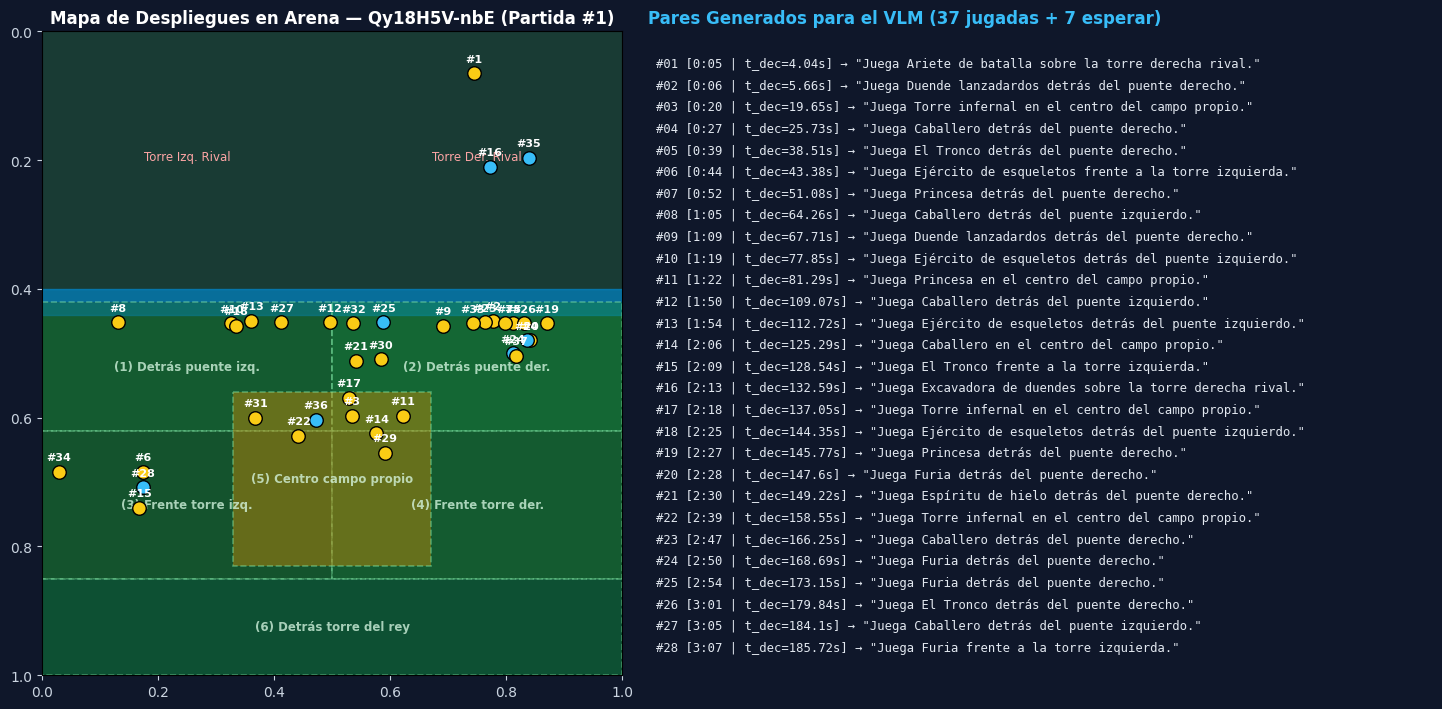

In [6]:
# =========================================================================
# VISUALIZACIÓN 1: MAPA TÁCTICO DE LAS 6 ZONAS Y PUNTOS DE CAÍDA EN LA ARENA
# (Muestra el mapa de la primera partida de cada video en selected_videos)
# =========================================================================
PLOT_VIDEO_FILTER = []   # 'all', 1, 'Qy18H5V-nbE', o [] para desactivar visualización

if not PLOT_VIDEO_FILTER or PLOT_VIDEO_FILTER == []:
    print('⏩ Visualización de mapa táctico desactivada (PLOT_VIDEO_FILTER está vacío).')
else:
    placed_ids_now = get_r2_ids_with_prefix('metadata/placements/', PLACEMENTS_DIR)
    pool_for_plot = [v for v in selected_videos if v['id'] in placed_ids_now or v['id'] in session_placements]
    plot_targets = select_videos(pool_for_plot, PLOT_VIDEO_FILTER)

    for item in plot_targets:
        vid = item['id']
        v_data = session_placements[vid] if vid in session_placements else load_r2_json(f'metadata/placements/{vid}.json', PLACEMENTS_DIR / f'{vid}.json')
        if not v_data.get('matches'):
            continue
    
        m_data = v_data['matches'][0]
        evs = m_data.get('events', [])
    
        fig, (ax_map, ax_tbl) = plt.subplots(1, 2, figsize=(15, 7.2), gridspec_kw={'width_ratios': [1.0, 1.35]}, facecolor='#0f172a')
        ax_map.set_facecolor('#14532d')
    
        # Dibujar las regiones del campo (río en y=0.42 y las 6 zonas propias)
        ax_map.axhspan(0.00, 0.42, color='#1e293b', alpha=0.55)
        ax_map.axhspan(0.40, 0.44, color='#0284c7', alpha=0.70, label='Río y Puentes')
    
        zones_rects = [
            (0.00, 0.42, 0.50, 0.20, '#166534', '(1) Detrás puente izq.'),
            (0.50, 0.42, 0.50, 0.20, '#15803d', '(2) Detrás puente der.'),
            (0.00, 0.62, 0.50, 0.23, '#14532d', '(3) Frente torre izq.'),
            (0.50, 0.62, 0.50, 0.23, '#166534', '(4) Frente torre der.'),
            (0.33, 0.56, 0.34, 0.27, '#ca8a04', '(5) Centro campo propio'),
            (0.00, 0.85, 1.00, 0.15, '#064e3b', '(6) Detrás torre del rey')
        ]
        for rx, ry, rw, rh, col, lbl in zones_rects:
            rect = mpatches.Rectangle((rx, ry), rw, rh, facecolor=col, edgecolor='#86efac', alpha=0.45, linewidth=1.2, linestyle='--')
            ax_map.add_patch(rect)
            ax_map.text(rx + rw/2, ry + rh/2, lbl, color='#dcfce7', fontsize=8.5, ha='center', va='center', alpha=0.75, fontweight='bold')
    
        ax_map.text(0.25, 0.20, 'Torre Izq. Rival', color='#fca5a5', fontsize=8.5, ha='center')
        ax_map.text(0.75, 0.20, 'Torre Der. Rival', color='#fca5a5', fontsize=8.5, ha='center')
    
        for ev in evs:
            xn, yn = ev['x_norm'], ev['y_norm']
            col_pt = '#38bdf8' if ev.get('is_global_card') else '#facc15'
            ax_map.scatter([xn], [yn], color=col_pt, edgecolor='black', s=95, zorder=6)
            ax_map.text(xn, yn - 0.018, f"#{ev['event_index']}", color='white', fontsize=8.0, fontweight='bold', ha='center', zorder=7)
    
        ax_map.set_xlim(0.0, 1.0)
        ax_map.set_ylim(1.0, 0.0)  # Invertido para que y=0 sea arriba (rival) e y=1 abajo (rey propio)
        ax_map.set_title(f'Mapa de Despliegues en Arena — {vid} (Partida #1)', color='white', fontsize=12, fontweight='bold')
        ax_map.tick_params(colors='#cbd5e1')
    
        # Panel derecho: Listado de las salidas VLM generadas
        ax_tbl.set_facecolor('#0f172a')
        ax_tbl.axis('off')
        ax_tbl.set_title(f'Pares Generados para el VLM ({len(evs)} jugadas + {len(m_data.get("wait_samples", []))} esperar)', color='#38bdf8', fontsize=12, fontweight='bold', loc='left')
    
        max_lines = 28
        for row_i, ev in enumerate(evs[:max_lines]):
            y_pos = 0.96 - row_i * (0.94 / max_lines)
            mmss = fmt_mmss(ev['t_drop_sec'])
            line_str = f"#{ev['event_index']:02d} [{mmss} | t_dec={ev['t_decision_sec']}s] → \"{ev['target_text']}\""
            ax_tbl.text(0.01, y_pos, line_str, color='#e2e8f0', fontsize=8.8, family='monospace', va='top')
    
        plt.tight_layout()
        plt.show()

In [ ]:
# =========================================================================
# VISUALIZACIÓN 2: VIDEO DE CONTRASTE EN TIEMPO REAL CON CUADRÍCULA Y MIRA EN ARENA
# - Lee directamente los JSON ya guardados en R2 (metadata/placements/<vid>.json).
# - Acotado a selected_videos para trabajo en paralelo con tus compañeros.
# - Para desactivar por completo: pon DEBUG_VIDEO_FILTER = []
# =========================================================================

DEBUG_VIDEO_FILTER = []     # 1, 2, 'Qy18H5V-nbE', 'all', o [] para desactivar
DEBUG_MATCH_FILTER = 1       # 1 = primera partida de cada video | 'all' = todas las partidas
SKIP_EXISTING_DEBUG = False  # Si True, si el video ya existe en R2 solo muestra el reproductor sin re-renderizar

def get_existing_r2_arena_debug_videos() -> set[str]:
    existing = set()
    try:
        res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='debug_videos/arena/')
        for item in res.get('Contents', []):
            existing.add(Path(item['Key']).name)
    except Exception:
        pass
    return existing

def generate_arena_verification_video(
    video_id: str,
    v_payload: dict,
    match_idx_in_list: int = 0,
    out_fps: int = 10,
    existing_files: set[str] = None
) -> str:
    m_data = v_payload['matches'][match_idx_in_list]
    m_num  = m_data.get('match_index', match_idx_in_list + 1)
    out_name = f'{video_id}_m{m_num}_arena_vlm.mp4'
    r2_debug_key = f'debug_videos/arena/{out_name}'

    if SKIP_EXISTING_DEBUG and existing_files and out_name in existing_files:
        cdn_video_url = f'{CDN_BASE}/{r2_debug_key}'
        print(f'⏩ Video arena {out_name} ya existe en R2 (reutilizando): {cdn_video_url}', flush=True)
        return cdn_video_url

    lay = layouts_dict[video_id]
    px = lay['boxes_pixel']
    start_sec = float(m_data['start_sec'])
    end_sec   = float(m_data['end_sec'])
    events    = m_data['events']
    tl        = m_data.get('timeline', [])

    tl_times  = np.array([p['t_sec'] for p in tl], dtype=np.float32) if tl else np.array([0.0])
    tl_elixir = np.array([p['elixir'] for p in tl], dtype=np.float32) if tl else np.array([0.0])

    video_path = download_video_from_cdn(video_id)
    cap = cv2.VideoCapture(str(video_path))
    orig_w, orig_h = lay['resolution']
    src_fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    step_f = max(1, int(round(src_fps / out_fps)))

    VIEW_H = 640
    scale = VIEW_H / float(orig_h)
    GAME_W = int(round(orig_w * scale))
    if GAME_W % 2 == 1:
        GAME_W += 1
    PANEL_W = 340
    CANVAS_W = GAME_W + PANEL_W

    out_mp4 = DEBUG_VIDEOS_DIR / out_name
    ffmpeg_cmd = [
        'ffmpeg', '-y',
        '-f', 'rawvideo', '-vcodec', 'rawvideo',
        '-s', f'{CANVAS_W}x{VIEW_H}', '-pix_fmt', 'rgb24', '-r', str(out_fps),
        '-i', '-',
        '-c:v', 'libx264', '-pix_fmt', 'yuv420p', '-preset', 'veryfast', '-crf', '25',
        '-movflags', '+faststart', str(out_mp4)
    ]

    print(f'🎬 Renderizando video VLM de arena {out_name} ({start_sec}s–{end_sec}s)...', flush=True)
    t0 = time.time()
    proc = subprocess.Popen(ffmpeg_cmd, stdin=subprocess.PIPE, stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

    cap.set(cv2.CAP_PROP_POS_MSEC, start_sec * 1000.0)
    f_idx = 0

    ax, ay, aw, ah = [int(v * scale) for v in px['arena_box']]
    scaled_slots = [[int(v * scale) for v in s] for s in px['card_slots']]

    while True:
        ret = cap.grab()
        if not ret:
            break
        if f_idx % step_f == 0:
            t_sec = cap.get(cv2.CAP_PROP_POS_MSEC) / 1000.0
            if t_sec > end_sec:
                break
            if t_sec >= start_sec:
                ok, frame_bgr = cap.retrieve()
                if ok and frame_bgr is not None:
                    game_rgb = cv2.cvtColor(cv2.resize(frame_bgr, (GAME_W, VIEW_H)), cv2.COLOR_BGR2RGB)
                    canvas = np.zeros((VIEW_H, CANVAS_W, 3), dtype=np.uint8)
                    canvas[:, :GAME_W] = game_rgb
                    canvas[:, GAME_W:] = (15, 23, 42)

                    cur_elix = float(tl_elixir[np.argmin(np.abs(tl_times - t_sec))])

                    # Dibujar cuadrícula sutil de las 6 zonas dentro de arena_box
                    cv2.rectangle(canvas, (ax, ay), (ax + aw, ay + ah), (0, 220, 220), 1)
                    y_river  = ay + int(ah * 0.42)
                    y_bridge = ay + int(ah * 0.62)
                    y_king   = ay + int(ah * 0.85)
                    x_mid    = ax + int(aw * 0.50)
                    cv2.line(canvas, (ax, y_river),  (ax + aw, y_river),  (56, 189, 248), 1)
                    cv2.line(canvas, (ax, y_bridge), (ax + aw, y_bridge), (74, 222, 128), 1)
                    cv2.line(canvas, (ax, y_king),   (ax + aw, y_king),   (74, 222, 128), 1)
                    cv2.line(canvas, (x_mid, y_river), (x_mid, y_king),   (74, 222, 128), 1)

                    # Recuadro de Zona 5 (Centro del campo propio)
                    zx0, zy0 = ax + int(aw * 0.33), ay + int(ah * 0.56)
                    zx1, zy1 = ax + int(aw * 0.67), ay + int(ah * 0.83)
                    cv2.rectangle(canvas, (zx0, zy0), (zx1, zy1), (250, 204, 21), 1)

                    active_ev = None
                    active_mode = None
                    last_ev = None
                    past_evs = []

                    for ev in events:
                        td = float(ev['t_drop_sec'])
                        if td <= t_sec + 0.1:
                            past_evs.append(ev)
                            last_ev = ev
                        if (td - 1.25) <= t_sec < (td - 0.45):
                            active_ev = ev
                            active_mode = 'DECISION'
                        elif (td - 0.45) <= t_sec <= (td + 1.45):
                            active_ev = ev
                            active_mode = 'DROP'

                    # Iluminar slot y dibujar MIRA (target crosshair) en el punto (x, y) de la arena
                    for s_i, (sx, sy, sw, sh) in enumerate(scaled_slots):
                        if active_ev and active_ev['hand_slot'] == s_i:
                            col_s = (250, 204, 21) if active_mode == 'DECISION' else (16, 185, 129)
                            cv2.rectangle(canvas, (sx-2, sy-2), (sx+sw+2, sy+sh+2), col_s, 3)
                        else:
                            cv2.rectangle(canvas, (sx, sy), (sx+sw, sy+sh), (0, 180, 100), 1)

                    if active_ev:
                        px_hit = ax + int(active_ev['x_norm'] * aw)
                        py_hit = ay + int(active_ev['y_norm'] * ah)
                        t_col = (250, 204, 21) if active_mode == 'DECISION' else (16, 185, 129)
                        if active_ev.get('spawn_method') == 'motion':
                            t_col = (239, 68, 68)  # rojo = ubicación por fallback de movimiento (menos fiable)
                        cv2.circle(canvas, (px_hit, py_hit), 22, t_col, 3)
                        cv2.circle(canvas, (px_hit, py_hit), 5, (255, 255, 255), -1)
                        cv2.line(canvas, (px_hit - 30, py_hit), (px_hit + 30, py_hit), t_col, 2)
                        cv2.line(canvas, (px_hit, py_hit - 30), (px_hit, py_hit + 30), t_col, 2)

                    # Panel derecho con la salida textual del VLM
                    px0 = GAME_W + 14
                    pil_img = Image.fromarray(canvas)
                    draw = ImageDraw.Draw(pil_img)

                    draw.text((px0, 14), f"Video: {video_id} (P#{m_num}) | t={t_sec:5.1f}s ({fmt_mmss(t_sec)})", fill=(248, 250, 252))
                    draw.text((px0, 36), f"Elixir en barra: {cur_elix:4.1f} / 10.0", fill=(244, 114, 182))

                    draw.text((px0, 74), "SALIDA VLM GENERADA:", fill=(148, 163, 184))
                    if last_ev:
                        draw.rectangle([px0, 96, CANVAS_W - 14, 168], fill=(6, 78, 59), outline=(16, 185, 129))
                        draw.text((px0 + 8, 104), f"#{last_ev['event_index']:02d} ({fmt_mmss(last_ev['t_drop_sec'])}) — Zona {last_ev['zone_id']}:", fill=(167, 243, 208))
                        draw.text((px0 + 8, 126), f'"{last_ev["target_text"]}"', fill=(255, 255, 255))
                        draw.text((px0 + 8, 147), f"Coord arena: ({last_ev['x_norm']:.2f}, {last_ev['y_norm']:.2f}) | {last_ev.get('spawn_method', '?')}{' | FUGA?' if last_ev.get('label_visible_at_decision') else ''}", fill=(203, 213, 225))

                    draw.text((px0, 185), f"HISTORIAL DE ACCIONES VLM ({len(past_evs)}/{len(events)}):", fill=(148, 163, 184))
                    for r_i, pev in enumerate(reversed(past_evs[-18:])):
                        y_t = 210 + r_i * 22
                        is_cur = (active_ev and active_ev['event_index'] == pev['event_index'])
                        col_t = (52, 211, 153) if is_cur else (203, 213, 225)
                        draw.text((px0, y_t), f"#{pev['event_index']:02d} [{fmt_mmss(pev['t_drop_sec'])}] {pev['target_text'][:38]}", fill=col_t)

                    proc.stdin.write(np.array(pil_img, dtype=np.uint8).tobytes())
        f_idx += 1

    cap.release()
    proc.stdin.close()
    proc.wait()

    mb = out_mp4.stat().st_size / (1024 * 1024)
    print(f'✔ Video VLM renderizado ({mb:.1f} MB en {time.time() - t0:.1f}s): {out_mp4}', flush=True)

    s3_client.upload_file(str(out_mp4), R2_BUCKET, r2_debug_key, ExtraArgs={'ContentType': 'video/mp4'})
    cdn_video_url = f'{CDN_BASE}/{r2_debug_key}?v={int(time.time())}'
    print(f'☁ Disponible en CDN: {cdn_video_url}', flush=True)
    return cdn_video_url

if not DEBUG_VIDEO_FILTER or DEBUG_VIDEO_FILTER in ([], 0, False):
    print('⏩ Generación de video de verificación desactivada (DEBUG_VIDEO_FILTER está vacío).')
else:
    placed_ids_debug = get_r2_ids_with_prefix('metadata/placements/', PLACEMENTS_DIR)
    pool_for_debug = [v for v in selected_videos if v['id'] in placed_ids_debug or v['id'] in session_placements]
    debug_targets = select_videos(pool_for_debug, DEBUG_VIDEO_FILTER)
    existing_arena_debug = get_existing_r2_arena_debug_videos()

    for item in debug_targets:
        vid = item['id']
        v_payload = session_placements[vid] if vid in session_placements else load_r2_json(f'metadata/placements/{vid}.json', PLACEMENTS_DIR / f'{vid}.json')
        matches_list = v_payload.get('matches', [])
        m_indices = list(range(len(matches_list))) if DEBUG_MATCH_FILTER == 'all' else list(range(min(int(DEBUG_MATCH_FILTER), len(matches_list))))

        for m_idx in m_indices:
            cdn_url = generate_arena_verification_video(vid, v_payload, match_idx_in_list=m_idx, out_fps=10, existing_files=existing_arena_debug)
            m_num = matches_list[m_idx].get('match_index', m_idx + 1)
            display(HTML(f"""
            <div style="background:#0f172a; padding:14px; border-radius:10px; display:inline-block; color:#f8fafc; font-family:sans-serif; margin-bottom:12px;">
              <div style="margin-bottom:8px; font-size:14px;">
                <b>🎯 Video de Verificación de Arena + Salida VLM ({vid} — Partida #{m_num})</b> — 
                <a href="{cdn_url}" target="_blank" style="color:#38bdf8;">Abrir en pestaña nueva (CDN)</a>
              </div>
              <video width="700" controls preload="metadata" style="border-radius:6px; border:1px solid #334155;">
                <source src="{cdn_url}" type="video/mp4">
              </video>
            </div>
            """))


🎬 Renderizando video VLM de arena Qy18H5V-nbE_m1_arena_vlm.mp4 (1.0s–231.0s)...
✔ Video VLM renderizado (7.8 MB en 128.7s): /kaggle/working/debug_videos/Qy18H5V-nbE_m1_arena_vlm.mp4
☁ Disponible en CDN: https://cdn-cr.eddux.dev/debug_videos/Qy18H5V-nbE_m1_arena_vlm.mp4?v=1792168919


# =========================================================================
# 08 — Exportación de los 4 Frames y Ensamble del Dataset VLM (JSONL)
# =========================================================================
Esta celda opcional corta los 4 frames canónicos ($t-6\text{s}, t-4\text{s}, t-2\text{s}, t_{\text{actual}}$)
para cada jugada y muestra de esperar, genera shards JSONL individuales por video
y consolida el archivo maestro `dataset/train.jsonl` en Cloudflare R2 sin pisar el trabajo de los demás.


In [8]:
# =========================================================================
# EXPORTACIÓN OPCIONAL DE LOS 4 FRAMES Y MANIFIESTO JSONL A CLOUDFLARE R2
# =========================================================================
EXPORT_DATASET_FRAMES = True   # Cambiar a True para generar los frames y el dataset final
EXPORT_VIDEO_FILTER = 'all'     # 'all', 1, 'Qy18H5V-nbE', o lista de IDs
SKIP_ALREADY_EXPORTED = True    # Salta videos cuyos shards ya estén en R2 para reanudar rápido
FRAME_EXPORT_SIZE = (540, 960)  # (ancho, alto) resolución normalizada para el VLM
JPEG_QUALITY = 85               # Calidad de compresión para ahorrar espacio y ancho de banda

EXPORT_IMG_DIR = DATASET_DIR / 'images'
EXPORT_SHARDS_DIR = DATASET_DIR / 'shards'
EXPORT_IMG_DIR.mkdir(parents=True, exist_ok=True)
EXPORT_SHARDS_DIR.mkdir(parents=True, exist_ok=True)

def export_vlm_sample_frames(
    cap: cv2.VideoCapture,
    timestamps: list[float],
    sample_id: str
) -> list[str]:
    saved_rel_paths = []
    suffixes = ['t-6s', 't-4s', 't-2s', 't-0s']
    for t_s, sfx in zip(timestamps, suffixes):
        cap.set(cv2.CAP_PROP_POS_MSEC, max(0.0, float(t_s)) * 1000.0)
        ok, frame_bgr = cap.read()
        if not ok or frame_bgr is None:
            continue
        resized = cv2.resize(frame_bgr, FRAME_EXPORT_SIZE, interpolation=cv2.INTER_AREA)
        rel_path = f"images/{sample_id}_{sfx}.jpg"
        out_jpg = DATASET_DIR / rel_path
        cv2.imwrite(str(out_jpg), resized, [cv2.IMWRITE_JPEG_QUALITY, JPEG_QUALITY])
        saved_rel_paths.append(rel_path)
    return saved_rel_paths

def consolidate_dataset_shards() -> dict:
    all_records = []
    for f in EXPORT_SHARDS_DIR.glob('*.jsonl'):
        for line in f.read_text(encoding='utf-8').splitlines():
            line = line.strip()
            if line:
                all_records.append(json.loads(line))
    try:
        res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='dataset/shards/')
        seen_vids = {r.get('video_id') for r in all_records}
        for item in res.get('Contents', []):
            stem = Path(item['Key']).stem
            if stem and stem not in seen_vids:
                obj = s3_client.get_object(Bucket=R2_BUCKET, Key=item['Key'])
                for line in obj['Body'].read().decode('utf-8').splitlines():
                    if line.strip():
                        all_records.append(json.loads(line))
    except Exception as e:
        print(f"⚠ Aviso consolidando shards en R2: {e}")

    train_jsonl = DATASET_DIR / 'train.jsonl'
    with open(train_jsonl, 'w', encoding='utf-8') as f:
        for r in all_records:
            f.write(json.dumps(r, ensure_ascii=False) + '\n')
    try:
        s3_client.upload_file(
            str(train_jsonl),
            R2_BUCKET,
            'dataset/train.jsonl',
            ExtraArgs={'ContentType': 'application/x-ndjson'}
        )
        print(f"☁ Manifiesto consolidado en R2: s3://{R2_BUCKET}/dataset/train.jsonl ({len(all_records)} muestras totales)")
    except Exception as e:
        print(f"⚠ Error subiendo train.jsonl a R2: {e}")
    return {'total_samples': len(all_records)}

if not EXPORT_DATASET_FRAMES:
    print('ℹ Exportación de frames desactivada (EXPORT_DATASET_FRAMES=False).')
    print('  Cambia EXPORT_DATASET_FRAMES = True en esta celda cuando quieras generar los paquetes de 4 frames y el dataset/train.jsonl en R2.')
else:
    placed_ids_export = get_r2_ids_with_prefix('metadata/placements/', PLACEMENTS_DIR)
    pool_for_export = [v for v in selected_videos if v['id'] in placed_ids_export or v['id'] in session_placements]
    export_targets = select_videos(pool_for_export, EXPORT_VIDEO_FILTER)
    print(f"🚀 Iniciando exportación de 4 frames para {len(export_targets)} video(s)...")

    exported_shards_r2 = set()
    try:
        res = s3_client.list_objects_v2(Bucket=R2_BUCKET, Prefix='dataset/shards/')
        for item in res.get('Contents', []):
            exported_shards_r2.add(Path(item['Key']).stem)
    except Exception:
        pass

    for item in export_targets:
        vid = item['id']
        if SKIP_ALREADY_EXPORTED and vid in exported_shards_r2 and len(export_targets) > 1:
            print(f'⏩ [{vid}] Shard ya exportado en R2, saltando.', flush=True)
            continue
        v_data = session_placements[vid] if vid in session_placements else load_r2_json(f'metadata/placements/{vid}.json', PLACEMENTS_DIR / f'{vid}.json')
        video_path = download_video_from_cdn(vid)
        cap = cv2.VideoCapture(str(video_path))

        shard_records = []
        for m_data in v_data.get('matches', []):
            m_idx = m_data.get('match_index', 0)
            for ev in m_data.get('events', []):
                sample_id = f"{vid}_m{m_idx}_play_{ev['event_index']:03d}"
                frames = export_vlm_sample_frames(cap, ev['vlm_frame_timestamps'], sample_id)
                if len(frames) == 4:
                    shard_records.append({
                        'sample_id': sample_id,
                        'video_id': vid,
                        'match_index': m_idx,
                        'action_type': 'play',
                        'timestamp_sec': ev['t_drop_sec'],
                        't_decision_sec': ev['t_decision_sec'],
                        'frames': frames,
                        'card_name_es': ev.get('card_name_es'),
                        'card_key': ev.get('card_key'),
                        'hand_slot': ev.get('hand_slot'),
                        'placement_coord': [ev['x_norm'], ev['y_norm']],
                        'placement_zone': ev['zone_phrase'],
                        'zone_id': ev['zone_id'],
                        'target_text': ev['target_text'],
                        'metadata': {
                            'spawn_method': ev.get('spawn_method'),
                            'spawn_conf': ev.get('spawn_conf'),
                            'label_visible_at_decision': ev.get('label_visible_at_decision')
                        }
                    })

            for w in m_data.get('wait_samples', []):
                sample_id = f"{vid}_m{m_idx}_wait_{w['wait_index']:03d}"
                frames = export_vlm_sample_frames(cap, w['vlm_frame_timestamps'], sample_id)
                if len(frames) == 4:
                    shard_records.append({
                        'sample_id': sample_id,
                        'video_id': vid,
                        'match_index': m_idx,
                        'action_type': 'wait',
                        'timestamp_sec': w['t_decision_sec'],
                        't_decision_sec': w['t_decision_sec'],
                        'frames': frames,
                        'card_name_es': None,
                        'card_key': None,
                        'hand_slot': None,
                        'placement_coord': None,
                        'placement_zone': None,
                        'zone_id': None,
                        'target_text': 'esperar',
                        'metadata': {
                            'gap_duration_sec': w.get('gap_duration_sec')
                        }
                    })

        cap.release()
        if DELETE_VIDEO_AFTER and video_path.exists():
            video_path.unlink(missing_ok=True)
        shard_file = EXPORT_SHARDS_DIR / f"{vid}.jsonl"
        with open(shard_file, 'w', encoding='utf-8') as f:
            for r in shard_records:
                f.write(json.dumps(r, ensure_ascii=False) + '\n')
        try:
            s3_client.upload_file(
                str(shard_file),
                R2_BUCKET,
                f"dataset/shards/{vid}.jsonl",
                ExtraArgs={'ContentType': 'application/x-ndjson'}
            )
            print(f"  ☁ [{vid}] Shard subido a R2: dataset/shards/{vid}.jsonl ({len(shard_records)} muestras)")
        except Exception as e:
            print(f"  ⚠ Error subiendo shard de {vid} a R2: {e}")

        img_list = list(EXPORT_IMG_DIR.glob(f"{vid}_*.jpg"))
        if img_list:
            t_up = time.time()
            def _upload_img(local_p):
                try:
                    s3_key = f"dataset/{local_p.relative_to(DATASET_DIR)}"
                    s3_client.upload_file(str(local_p), R2_BUCKET, s3_key, ExtraArgs={'ContentType': 'image/jpeg'})
                except Exception:
                    pass
            with ThreadPoolExecutor(max_workers=16) as pool:
                list(pool.map(_upload_img, img_list))
            print(f"  ☁ [{vid}] {len(img_list)} imágenes subidas a R2 en {time.time() - t_up:.1f}s")
            if DELETE_VIDEO_AFTER:
                for img_p in img_list:
                    img_p.unlink(missing_ok=True)

    consolidate_dataset_shards()


ℹ Exportación de frames desactivada (EXPORT_DATASET_FRAMES=False).
  Cambia EXPORT_DATASET_FRAMES = True en esta celda cuando quieras generar los paquetes de 4 frames y el dataset/train.jsonl en R2.
